# **Sequential Fixed-Width Confidence Interval Estimation**

Experiment: We want to measure the average height of male adults in Mauritius. Let us assume that their heights are normally distributed in the population $\mathcal{P} = [x_1, x_2, ..., x_N]$. We create the population, 

In [2]:
# Importing,
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

N = 600000
mu, sigma = 173, 7
pop = np.random.normal(loc=mu, scale=sigma, size=N)

Our sequential algorithm is, 

$$
N = \text{inf} \{ n \geq n_0 : \frac{z\hat{s}_n}{\sqrt{n}} \leq \epsilon \}
$$

Performing a single trial run,

Halting Size: 670, Epsilon: 0.49983995111366003


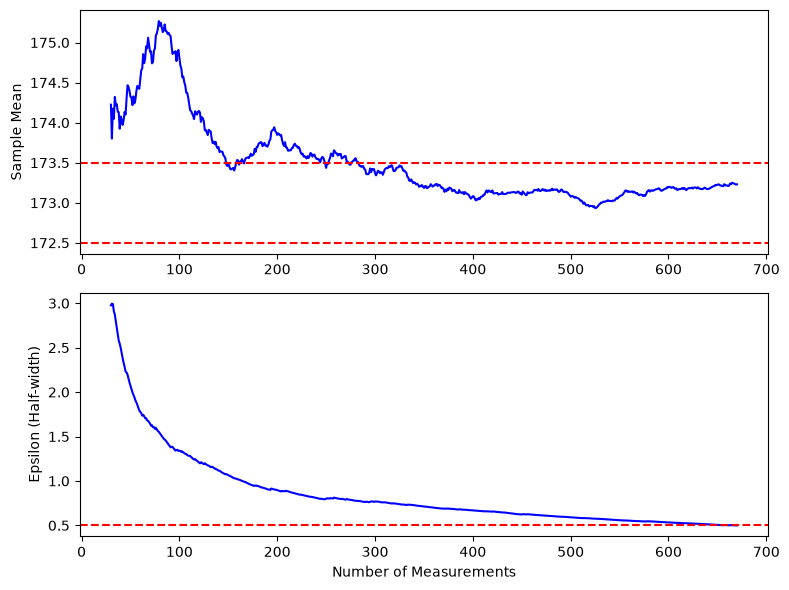

In [37]:
# PARAMETERS,
z=1.96
epsilon = 0.5
n_min = 30
n_max = 10000

# Initialising arrays,
sample = np.empty(n_max) # <-- Preallocate array.
sample[:n_min] = np.random.choice(pop, size=n_min, replace=True)
means = []
stds = []
epsilons = []

# Sequential loop,
n = n_min
while True:

    # Computing current epsilon, 
    epsilon_current = (z*np.std(sample[:n], ddof=1))/np.sqrt(n)
    means.append(np.mean(sample[:n]).item())
    stds.append(np.std(sample[:n], ddof=1).item())
    epsilons.append(epsilon_current)

    # Halting if condition is met,
    if epsilon_current <= epsilon:
        print(f"Halting Size: {n}, Epsilon: {epsilon_current}")
        break

    # Taking another measurement,
    sample[n] = np.random.choice(pop, size=1, replace=True).item()
    n += 1

# Visualising,
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
x_tick_labels = np.arange(start=n_min, stop=n+1, step=1)

axes[0].plot(x_tick_labels, means, color="blue")
axes[0].axhline(y=mu + epsilon, linestyle="--", color="red")
axes[0].axhline(y=mu - epsilon, linestyle="--", color="red")
axes[0].set_ylabel("Sample Mean")

axes[1].plot(x_tick_labels, epsilons, color="blue")
axes[1].axhline(y=epsilon, linestyle="--", color="red")
axes[1].set_xlabel("Number of Measurements")
axes[1].set_ylabel("Epsilon (Half-width)")

plt.tight_layout()
plt.show()

### 2. Running The Experiments

Packing the experiment into a helper function,

In [157]:
def run_experiment(population, n_trials, m, epsilon, n, n_min):
    """Helper function to run the experiment for multiple trials and collect results."""

    experiment_results = {"halting_size": [], "mean": [], "std": []}
    for trial in range(n_trials):
        # Creating sample,
        sample = np.random.choice(population, size=n, replace=True)

        # Sequentially checking halting condition,
        for i in range(n_min, n):
            epsilon_current = (m*np.std(sample[:i], ddof=1))/np.sqrt(i)
            if epsilon_current <= epsilon:
                experiment_results["halting_size"].append(i)
                break

        # Computing stats,
        experiment_results["mean"].append(np.mean(sample[:i]).item())
        experiment_results["std"].append(np.std(sample[:i], ddof=1).item())
    return experiment_results

Now we finally run the experiment,

In [160]:
# PARAMETERS,
n_trials=2500
n=1000
m=1.96 # 95% confidence interval.
epsilon = 0.5 # Nearest cm.
n_min = 50 # Minimum sample size.

results = run_experiment(pop, n_trials, m, epsilon, n, n_min)
df = pd.DataFrame(results)

Visualising the distribution of halting times,

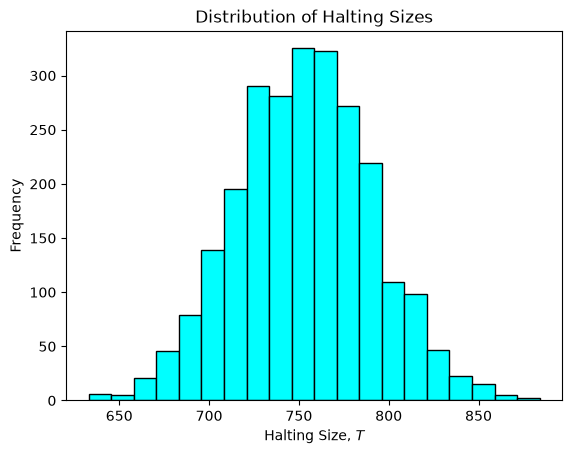

In [161]:
plt.hist(results["halting_size"], bins=20, edgecolor="black", color="cyan")
plt.xlabel("Halting Size, $T$")
plt.ylabel("Frequency")
plt.title("Distribution of Halting Sizes")
plt.show()

Checking if confidence interval is met,

In [162]:
prob = 1 - np.mean(np.abs(np.array(results["mean"]) - mu) >= epsilon)
prob.item()

0.952